# Trabalho 07 – Reconhecimento de Dígitos com Perceptron Multicamadas (base MNIST)

**Disciplina:** EL056 – Redes Neurais Artificiais (PPGEELT/UFU)

**Enunciado.** Treinar uma MLP para reconhecer dígitos. Nesta versão a base de treinamento é o MNIST (LeCun et al., 1998): 60.000 dígitos manuscritos para treino e 10.000 para teste, em imagens de 28×28 pixels. Os dígitos das cinco fontes do enunciado são usados como teste adicional de generalização.

As células de código são extraídas do programa `trabalho07_mnist.py`. Execute o notebook a partir da pasta `trabalho07_mnist/`, que contém `dados/mnist/` e `fontes/`. A execução completa leva poucos minutos.

## 1. Configuração

Parâmetros da base, da rede e dos experimentos. Se os arquivos `.gz` do MNIST não estiverem em `dados/mnist/`, o programa tenta baixá-los de espelhos públicos.

In [1]:
import argparse
import gzip
import json
import os
import time
import urllib.request
import warnings

import numpy as np
from PIL import Image, ImageDraw, ImageFont

import matplotlib
matplotlib.use("Agg")                      # gera figuras sem abrir janelas
import matplotlib.pyplot as plt

# =====================================================================
# CONFIGURAÇÃO GERAL (altere aqui)
# =====================================================================

PASTA_SCRIPT = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
PASTA_MNIST = os.path.join(PASTA_SCRIPT, "dados", "mnist")

# Arquivos originais do MNIST (formato IDX compactado) e espelhos para
# download automático, caso não estejam na pasta dados/mnist/.
ARQUIVOS_MNIST = {
    "X_treino": "train-images-idx3-ubyte.gz",
    "y_treino": "train-labels-idx1-ubyte.gz",
    "X_teste": "t10k-images-idx3-ubyte.gz",
    "y_teste": "t10k-labels-idx1-ubyte.gz",
}
ESPELHOS_MNIST = [
    "https://ossci-datasets.s3.amazonaws.com/mnist",
    "https://storage.googleapis.com/cvdf-datasets/mnist",
    "https://raw.githubusercontent.com/fgnt/mnist/master",
]

LADO = 28                        # imagens 28 x 28 = 784 entradas
LIMIAR = 0.5                     # intensidade (0-1) mínima para o pixel virar +1
N_VALIDACAO = 5000               # últimas imagens do treino separadas para validação

# ---- Hiperparâmetros da MLP ----
N_OCULTOS = 100                  # neurônios na camada oculta
ALFA = 0.01                      # taxa de aprendizagem
MOMENTO = 0.5                    # termo de momento (0 desativa)
TAM_LOTE = 32                    # padrões por atualização (1 = padrão a padrão)
TOLERANCIA = 0.05                # erro quadrático médio por padrão para parada
MAX_EPOCAS = 30                  # limite de épocas
SEMENTE = 2026                   # semente global (reprodutibilidade)
# Pesos iniciais ~ U(-1/sqrt(n), +1/sqrt(n)), n = nº de entradas do neurônio
# (incluindo o bias). Com 784 entradas, uma amplitude fixa como 0,5
# saturaria a tanh logo no início do treinamento.

# ---- Experimentos ----
NIVEIS_RUIDO = [0.0, 0.05, 0.10, 0.15, 0.20]     # fração de pixels invertidos
REPETICOES_RUIDO = 30                             # repetições por nível
OCULTOS_SENSIBILIDADE = [25, 50, 100, 200]        # estudo de sensibilidade
EPOCAS_SENSIBILIDADE = 20                         # épocas por configuração
EPOCAS_SEM_MOMENTO = MAX_EPOCAS                   # treino de comparação (momento = 0)

# ---- Teste com dígitos impressos (as cinco fontes do enunciado) ----
FONTES = [
    ("Sem serifa negrito (DejaVu Sans Bold)",
     ["DejaVuSans-Bold.ttf", "LiberationSans-Bold.ttf", "arialbd.ttf", "Arial Bold.ttf"]),
    ("Serifada regular (Liberation Serif)",
     ["LiberationSerif-Regular.ttf", "times.ttf", "Times New Roman.ttf", "DejaVuSerif.ttf"]),
    ("Sem serifa fina (DejaVu Sans ExtraLight)",
     ["DejaVuSans-ExtraLight.ttf", "Poppins-Light.ttf", "segoeuil.ttf", "LiberationSans-Regular.ttf"]),
    ("Manuscrita/cursiva (Kalam)",
     ["Kalam-Regular.ttf", "segoepr.ttf", "LiberationSerif-Italic.ttf", "DejaVuSerif-Italic.ttf"]),
    ("Serifada condensada (DejaVu Serif Condensed)",
     ["DejaVuSerifCondensed.ttf", "DejaVuSerif.ttf", "georgia.ttf", "LiberationSerif-Regular.ttf"]),
]
PASTAS_FONTES = [
    os.path.join(PASTA_SCRIPT, "fontes"),
    "/usr/share/fonts", "/usr/local/share/fonts",
    os.path.expanduser("~/.fonts"), os.path.expanduser("~/.local/share/fonts"),
    "/Library/Fonts", "/System/Library/Fonts", os.path.expanduser("~/Library/Fonts"),
    "C:/Windows/Fonts",
]
DIGITOS = ["1", "2", "3", "4", "5", "6", "7", "8", "9", "0"]   # ordem do enunciado
TAMANHO_FONTE = 200              # tamanho (pt) da renderização em alta resolução

# Cores das figuras (tons sóbrios, adequados à impressão)
COR_PRINCIPAL = "#2a78d6"
COR_SECUNDARIA = "#eb6834"
COR_TEXTO = "#52514e"


## 2. Base de dados MNIST

Os arquivos originais estão no formato IDX: um cabeçalho (16 bytes para imagens, 8 para rótulos) seguido dos bytes dos pixels (0–255) ou dos rótulos (0–9). As intensidades são normalizadas para $[0,1]$ e binarizadas em $0{,}5$: pixels de tinta recebem $+1$ e o fundo $-1$, a mesma representação bipolar dos trabalhos anteriores. Cada padrão tem $28\times 28 = 784$ entradas.

As 5.000 últimas imagens do treino formam o conjunto de **validação**, usado para escolher a melhor época. O conjunto de **teste** (10.000 imagens) só é usado na avaliação final.

O ruído inverte o sinal de uma fração exata dos 784 pixels de cada imagem.

In [2]:
# =====================================================================
# 1. BASE DE DADOS MNIST
# =====================================================================

def _baixar(nome, pasta):
    """Tenta baixar um arquivo do MNIST dos espelhos configurados."""
    os.makedirs(pasta, exist_ok=True)
    destino = os.path.join(pasta, nome)
    for base in ESPELHOS_MNIST:
        try:
            print(f"    baixando {nome} de {base} ...")
            urllib.request.urlretrieve(f"{base}/{nome}", destino)
            return destino
        except Exception as erro:                       # tenta o próximo espelho
            warnings.warn(f"Falha ao baixar de {base}: {erro}")
    raise FileNotFoundError(f"Não foi possível obter {nome}. Copie os arquivos do MNIST "
                            f"para {pasta}.")


def _ler_idx(caminho, deslocamento):
    """Lê um arquivo IDX compactado (cabeçalho de 'deslocamento' bytes)."""
    with gzip.open(caminho, "rb") as fp:
        return np.frombuffer(fp.read(), dtype=np.uint8, offset=deslocamento)


def carregar_mnist(pasta=PASTA_MNIST):
    """Devolve (X_treino, y_treino, X_teste, y_teste) com intensidades em [0, 1]."""
    dados = {}
    for chave, nome in ARQUIVOS_MNIST.items():
        caminho = os.path.join(pasta, nome)
        if not os.path.isfile(caminho):
            caminho = _baixar(nome, pasta)
        if chave.startswith("X"):
            dados[chave] = _ler_idx(caminho, 16).reshape(-1, LADO * LADO).astype(float) / 255.0
        else:
            dados[chave] = _ler_idx(caminho, 8).astype(int)
    return dados["X_treino"], dados["y_treino"], dados["X_teste"], dados["y_teste"]


def bipolarizar(X, limiar=LIMIAR):
    """Binariza as intensidades e converte para a representação bipolar (-1/+1)."""
    return np.where(X >= limiar, 1.0, -1.0)


def adicionar_ruido(X, fracao, rng):
    """Inverte o sinal de uma fração exata dos pixels de cada padrão (ruído)."""
    n_pad, n = X.shape
    k = int(round(fracao * n))
    if k == 0:
        return X.copy()
    # sorteio vetorizado de k posições distintas por padrão
    idx = np.argsort(rng.random((n_pad, n)), axis=1)[:, :k]
    Xr = X.copy()
    np.put_along_axis(Xr, idx, -np.take_along_axis(Xr, idx, axis=1), axis=1)
    return Xr


def codificar_alvos(y, n_classes=10):
    """Codificação bipolar one-hot: +1 na classe correta, -1 nas demais."""
    T = -np.ones((len(y), n_classes))
    T[np.arange(len(y)), y] = 1.0
    return T


## 3. Dígitos impressos no formato do MNIST

Para testar a rede em dígitos de outra natureza, os dez dígitos das cinco fontes do enunciado passam pelo mesmo pré-processamento do MNIST: o dígito é ajustado a uma caixa de $20\times20$ pixels (mantendo a proporção) e centralizado pelo centro de massa numa imagem de $28\times28$.

In [3]:
# =====================================================================
# 2. DÍGITOS IMPRESSOS NO FORMATO DO MNIST
# =====================================================================

def _indexar_pastas(pastas):
    """Percorre as pastas de fontes uma única vez e devolve {nome_minúsculo: caminho}."""
    indice = {}
    for pasta in pastas:
        if not os.path.isdir(pasta):
            continue
        for raiz, _, arquivos in os.walk(pasta):
            for arq in arquivos:
                if arq.lower().endswith((".ttf", ".otf")):
                    indice.setdefault(arq.lower(), os.path.join(raiz, arq))
    return indice


def localizar_fontes(fontes=FONTES, pastas=PASTAS_FONTES, tamanho=TAMANHO_FONTE):
    """Carrega as fontes configuradas, com aviso e alternativa quando faltarem."""
    indice = _indexar_pastas(pastas)
    carregadas = []
    for rotulo, candidatos in fontes:
        caminho = None
        for i, cand in enumerate(candidatos):
            achado = cand if os.path.isfile(cand) else indice.get(os.path.basename(cand).lower())
            if achado:
                caminho = achado
                if i > 0:
                    warnings.warn(f"Fonte preferida '{candidatos[0]}' não encontrada para "
                                  f"'{rotulo}'; usando alternativa '{cand}'.")
                break
        if caminho is None:
            warnings.warn(f"Nenhuma fonte encontrada para '{rotulo}'; usando a fonte padrão do Pillow.")
            fonte, caminho = ImageFont.load_default(size=tamanho), "<padrão do Pillow>"
        else:
            fonte = ImageFont.truetype(caminho, tamanho)
        carregadas.append((rotulo, caminho, fonte))
    return carregadas


def renderizar_mnist(fonte, digito):
    """Renderiza um dígito com o mesmo pré-processamento do MNIST.

    O MNIST normaliza cada dígito para caber numa caixa de 20 x 20 pixels
    (mantendo a proporção) e o centraliza pelo centro de massa numa imagem
    de 28 x 28 (LeCun et al., 1998).
    """
    lado = 3 * TAMANHO_FONTE
    img = Image.new("L", (lado, lado), 0)                    # fundo 0, tinta 255
    ImageDraw.Draw(img).text((lado // 3, lado // 6), digito, font=fonte, fill=255)
    recorte = img.crop(img.getbbox())                        # caixa delimitadora
    w, h = recorte.size
    escala = 20.0 / max(w, h)
    novo = (max(1, round(w * escala)), max(1, round(h * escala)))
    pequeno = np.asarray(recorte.resize(novo, Image.LANCZOS), dtype=float) / 255.0
    pequeno = np.clip(pequeno, 0, 1)

    # centralização pelo centro de massa
    ys, xs = np.indices(pequeno.shape)
    massa = pequeno.sum()
    cy, cx = (ys * pequeno).sum() / massa, (xs * pequeno).sum() / massa
    saida = np.zeros((LADO, LADO))
    y0, x0 = int(round(LADO / 2 - cy)), int(round(LADO / 2 - cx))
    y0 = min(max(y0, 0), LADO - pequeno.shape[0])
    x0 = min(max(x0, 0), LADO - pequeno.shape[1])
    saida[y0:y0 + pequeno.shape[0], x0:x0 + pequeno.shape[1]] = pequeno
    return saida.ravel()


def construir_base_fontes(fontes_carregadas):
    """50 padrões (10 dígitos x 5 fontes) no formato do MNIST, intensidades em [0, 1]."""
    X, y, id_fonte = [], [], []
    for f, (_, _, fonte) in enumerate(fontes_carregadas):
        for d in DIGITOS:
            X.append(renderizar_mnist(fonte, d))
            y.append(int(d))
            id_fonte.append(f)
    return np.array(X), np.array(y), np.array(id_fonte)


## 4. Perceptron multicamadas e *backpropagation*

A rede tem $n = 784$ entradas $x_i$, $p$ neurônios ocultos $z_j$ e $m = 10$ saídas $y_k$ (notação de Fausett, 1994):

$$z_j = f\Big(v_{0j} + \sum_{i=1}^{n} x_i v_{ij}\Big), \qquad y_k = f\Big(w_{0k} + \sum_{j=1}^{p} z_j w_{jk}\Big), \qquad f(x) = \tanh(x),\ f'(x) = 1 - f(x)^2 .$$

Saídas desejadas em codificação bipolar *one-hot* ($t_k = +1$ na classe correta e $-1$ nas demais). Termos de erro (Rumelhart; Hinton; Williams, 1986):

$$\delta_k = (t_k - y_k)\, f'(y\_in_k), \qquad \delta_j = f'(z\_in_j) \sum_{k=1}^{m} \delta_k\, w_{jk}.$$

Com 55.000 padrões, a atualização padrão a padrão em Python seria lenta. Por isso as correções usam a média do gradiente em **mini-lotes** de $B = 32$ padrões, com momento $\mu$:

$$\Delta w_{jk}(t) = \frac{\alpha}{B} \sum_{p \in \text{lote}} \delta_k^{(p)} z_j^{(p)} + \mu\, \Delta w_{jk}(t-1), \qquad \Delta v_{ij}(t) = \frac{\alpha}{B} \sum_{p \in \text{lote}} \delta_j^{(p)} x_i^{(p)} + \mu\, \Delta v_{ij}(t-1).$$

Com $B = 1$ obtém-se o algoritmo padrão a padrão. O treinamento para quando o erro quadrático médio por padrão, $E_{\text{total}}/P$, fica abaixo da tolerância ou no limite de épocas. Ao final, restauram-se os pesos da época de maior acurácia de validação.

**Inicialização.** Os pesos de cada camada são sorteados em $U(-1/\sqrt{n},\, 1/\sqrt{n})$, com $n$ igual ao número de entradas do neurônio (bias incluído). Uma amplitude fixa como $0{,}5$, com 784 entradas, saturaria a $\tanh$ logo no início. Nos ensaios preliminares, taxas $\alpha \geq 0{,}05$ com momento $0{,}9$ fizeram o treino divergir.

In [4]:
# =====================================================================
# 3. REDE MLP (implementação própria em NumPy)
# =====================================================================

class MLP:
    """Perceptron multicamadas com uma camada oculta e ativação tanh.

    V : pesos entrada -> oculta, forma (n_entradas + 1, n_ocultos); linha 0 = bias
    W : pesos oculta -> saída,   forma (n_ocultos + 1, n_saidas);  linha 0 = bias
    """

    def __init__(self, n_entradas, n_ocultos, n_saidas, semente=SEMENTE):
        rng = np.random.default_rng(semente)
        a_v = 1.0 / np.sqrt(n_entradas + 1)
        a_w = 1.0 / np.sqrt(n_ocultos + 1)
        self.V = rng.uniform(-a_v, a_v, (n_entradas + 1, n_ocultos))
        self.W = rng.uniform(-a_w, a_w, (n_ocultos + 1, n_saidas))
        self.rng = rng

    @staticmethod
    def f(x):
        """Função de ativação: tangente hiperbólica (sigmoide bipolar)."""
        return np.tanh(x)

    @staticmethod
    def df(fx):
        """Derivada da tanh escrita em função da própria saída: 1 - f(x)^2."""
        return 1.0 - fx ** 2

    def propagar(self, X):
        """Fase direta para um lote de padrões (uma linha por padrão)."""
        Z = self.f(X @ self.V[1:] + self.V[0])      # saídas da camada oculta
        Y = self.f(Z @ self.W[1:] + self.W[0])      # saídas da rede
        return Z, Y

    def erro_medio(self, X, T, lote=10000):
        """Erro quadrático médio por padrão: E_total / P, E_total = 1/2 soma (t - y)^2."""
        E = 0.0
        for i in range(0, len(X), lote):
            _, Y = self.propagar(X[i:i + lote])
            E += 0.5 * float(np.sum((T[i:i + lote] - Y) ** 2))
        return E / len(X)

    def classificar(self, X, lote=10000):
        """Classe = índice do neurônio de saída com maior valor."""
        return np.concatenate([np.argmax(self.propagar(X[i:i + lote])[1], axis=1)
                               for i in range(0, len(X), lote)])

    def copiar_pesos(self):
        return self.V.copy(), self.W.copy()

    def treinar(self, X, T, X_val=None, y_val=None, alfa=ALFA, momento=MOMENTO,
                tam_lote=TAM_LOTE, tolerancia=TOLERANCIA, max_epocas=MAX_EPOCAS,
                verboso=False):
        """Backpropagation com momento, em mini-lotes (tam_lote = 1 -> padrão a padrão).

        Parada: erro quadrático médio por padrão < tolerância ou máximo de épocas.
        Se houver conjunto de validação, os pesos da época de maior acurácia de
        validação são restaurados ao final.
        Retorna um dicionário com o histórico por época.
        """
        dV_ant = np.zeros_like(self.V)
        dW_ant = np.zeros_like(self.W)
        hist = {"erro_treino": [], "erro_val": [], "acc_val": [], "tempo": []}
        melhor_acc, melhores_pesos, melhor_epoca = -1.0, None, 0
        t0 = time.time()
        for epoca in range(1, max_epocas + 1):
            ordem = self.rng.permutation(len(X))
            for ini in range(0, len(X), tam_lote):
                idx = ordem[ini:ini + tam_lote]
                x, t = X[idx], T[idx]
                # --- fase direta ---
                z, yv = self.propagar(x)
                # --- retropropagação do erro ---
                delta_k = (t - yv) * self.df(yv)                 # termos de erro da saída
                delta_j = (delta_k @ self.W[1:].T) * self.df(z)  # termos de erro da oculta
                # --- correções (gradiente médio do lote + momento) ---
                n = len(idx)
                gW = np.vstack([delta_k.sum(axis=0), z.T @ delta_k]) / n
                gV = np.vstack([delta_j.sum(axis=0), x.T @ delta_j]) / n
                dW = alfa * gW + momento * dW_ant
                dV = alfa * gV + momento * dV_ant
                self.W += dW
                self.V += dV
                dW_ant, dV_ant = dW, dV

            E = self.erro_medio(X, T)
            hist["erro_treino"].append(E)
            hist["tempo"].append(time.time() - t0)
            if X_val is not None:
                hist["erro_val"].append(self.erro_medio(X_val, codificar_alvos(y_val)))
                acc = float(np.mean(self.classificar(X_val) == y_val))
                hist["acc_val"].append(acc)
                if acc > melhor_acc:
                    melhor_acc, melhores_pesos, melhor_epoca = acc, self.copiar_pesos(), epoca
            if verboso:
                extra = f"  acc_val = {100 * hist['acc_val'][-1]:.2f}%" if X_val is not None else ""
                print(f"  época {epoca:3d}  E/P = {E:.4f}{extra}  ({hist['tempo'][-1]:.0f} s)")
            if E < tolerancia:
                break
        if melhores_pesos is not None:
            self.V, self.W = melhores_pesos
        hist["melhor_epoca"] = melhor_epoca
        return hist


def acuracia(rede, X, y):
    return float(np.mean(rede.classificar(X) == y))


## 5. Experimentos

1. Treino 784–100–10, com curvas de erro e acurácia de validação, e o mesmo treino sem momento;
2. acurácia de teste e matriz de confusão;
3. robustez a ruído no teste (30 repetições por nível);
4. dígitos impressos das cinco fontes do enunciado;
5. sensibilidade ao número de neurônios ocultos (25, 50, 100, 200).

In [5]:
# =====================================================================
# 4. EXPERIMENTOS
# =====================================================================

def matriz_confusao(y_real, y_prev, n=10):
    M = np.zeros((n, n), dtype=int)
    np.add.at(M, (y_real, y_prev), 1)
    return M


def teste_ruido(rede, X, y, niveis=NIVEIS_RUIDO, repeticoes=REPETICOES_RUIDO, semente=SEMENTE):
    """Acurácia média (e desvio) no conjunto de teste para cada nível de ruído."""
    rng = np.random.default_rng(semente + 1)
    medias, desvios = [], []
    for nivel in niveis:
        reps = 1 if nivel == 0 else repeticoes
        accs = [acuracia(rede, adicionar_ruido(X, nivel, rng), y) for _ in range(reps)]
        medias.append(float(np.mean(accs)))
        desvios.append(float(np.std(accs)))
    return medias, desvios


def sensibilidade_ocultos(Xtr, Ttr, Xval, yval, Xte, yte, lista=OCULTOS_SENSIBILIDADE,
                          epocas=EPOCAS_SENSIBILIDADE):
    """Varia o nº de neurônios ocultos: acurácia de teste, com 10% de ruído e tempo."""
    saida = []
    for n in lista:
        rede = MLP(Xtr.shape[1], n, 10, semente=SEMENTE)
        hist = rede.treinar(Xtr, Ttr, Xval, yval, max_epocas=epocas)
        m, d = teste_ruido(rede, Xte, yte, niveis=[0.10], repeticoes=10)
        r = {
            "n_ocultos": n,
            "n_pesos": int(rede.V.size + rede.W.size),
            "melhor_epoca": hist["melhor_epoca"],
            "acuracia_val": max(hist["acc_val"]),
            "acuracia_teste": acuracia(rede, Xte, yte),
            "acuracia_teste_ruido10": m[0],
            "tempo_s": round(hist["tempo"][-1], 1),
        }
        print(f"    {n:4d} ocultos: teste = {100 * r['acuracia_teste']:.2f}%, "
              f"10% ruído = {100 * m[0]:.2f}%, {r['tempo_s']} s")
        saida.append(r)
    return saida


## 6. Funções de gráficos

In [6]:
# =====================================================================
# 5. GRÁFICOS
# =====================================================================

def _estilo():
    plt.rcParams.update({
        "font.size": 10, "axes.edgecolor": COR_TEXTO, "axes.labelcolor": "#0b0b0b",
        "xtick.color": COR_TEXTO, "ytick.color": COR_TEXTO,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
        "savefig.dpi": 200, "savefig.bbox": "tight",
    })


def _grade_imagens(imagens, rotulos_linhas, caminho, titulos=None, cmap="gray_r"):
    """Desenha uma grade de imagens 28 x 28 (uma linha por grupo)."""
    n_l, n_c = len(imagens), len(imagens[0])
    fig, eixos = plt.subplots(n_l, n_c, figsize=(n_c * 0.72, n_l * 0.8))
    eixos = np.atleast_2d(eixos)
    for i in range(n_l):
        for j in range(n_c):
            ax = eixos[i, j]
            ax.imshow(imagens[i][j].reshape(LADO, LADO), cmap=cmap, vmin=-1, vmax=1,
                      interpolation="nearest")
            ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            for s in ax.spines.values():
                s.set_visible(True); s.set_color("#c3c2b7"); s.set_linewidth(0.5)
            if titulos is not None:
                ax.set_title(titulos[i][j], fontsize=7, color=COR_TEXTO, pad=2)
        eixos[i, 0].set_ylabel(rotulos_linhas[i], rotation=0, labelpad=14, va="center", fontsize=9)
    fig.tight_layout(pad=0.3)
    fig.savefig(caminho)
    plt.close(fig)


def fig_base(X, y, caminho, por_digito=5):
    """Grade 5 x 10: os primeiros 'por_digito' exemplos de cada dígito (bipolar)."""
    colunas = [np.flatnonzero(y == int(d))[:por_digito] for d in DIGITOS]
    imagens = [[X[colunas[j][i]] for j in range(len(DIGITOS))] for i in range(por_digito)]
    _grade_imagens(imagens, [f"#{i + 1}" for i in range(por_digito)], caminho)


def fig_fontes(X, n_fontes, caminho):
    """Dígitos impressos convertidos para o formato do MNIST (bipolar)."""
    imagens = [list(X[f * 10:(f + 1) * 10]) for f in range(n_fontes)]
    _grade_imagens(imagens, [f"F{f + 1}" for f in range(n_fontes)], caminho)


def fig_curva_erro(hist, hist_sm, caminho):
    fig, eixos = plt.subplots(1, 2, figsize=(9, 3.3))
    ep = np.arange(1, len(hist["erro_treino"]) + 1)
    ep_sm = np.arange(1, len(hist_sm["erro_treino"]) + 1)
    ax = eixos[0]
    ax.plot(ep, hist["erro_treino"], color=COR_PRINCIPAL, lw=1.8, label="treino (momento 0,5)")
    ax.plot(ep, hist["erro_val"], color=COR_PRINCIPAL, lw=1.4, ls="--", label="validação (momento 0,5)")
    ax.plot(ep_sm, hist_sm["erro_treino"], color=COR_SECUNDARIA, lw=1.8, label="treino (sem momento)")
    ax.set_xlabel("Época"); ax.set_ylabel("Erro quadrático médio por padrão")
    ax.legend(fontsize=8, frameon=False)
    ax = eixos[1]
    ax.plot(ep, 100 * np.array(hist["acc_val"]), color=COR_PRINCIPAL, lw=1.8, marker="o", ms=3,
            label="momento 0,5")
    ax.plot(ep_sm, 100 * np.array(hist_sm["acc_val"]), color=COR_SECUNDARIA, lw=1.8, marker="o",
            ms=3, label="sem momento")
    ax.axvline(hist["melhor_epoca"], color=COR_TEXTO, lw=0.8, ls=":")
    ax.set_xlabel("Época"); ax.set_ylabel("Acurácia de validação (%)")
    ax.legend(fontsize=8, frameon=False, loc="lower right")
    fig.tight_layout()
    fig.savefig(caminho)
    plt.close(fig)


def fig_confusao(M, caminho):
    fig, ax = plt.subplots(figsize=(5.2, 4.4))
    # escala logarítmica para que os erros (fora da diagonal) fiquem visíveis
    ax.imshow(np.log1p(M), cmap="Blues")
    ax.grid(False)
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    ax.set_xlabel("Classe prevista"); ax.set_ylabel("Classe real")
    lim = np.log1p(M).max() / 2
    for i in range(10):
        for j in range(10):
            if M[i, j]:
                ax.text(j, i, M[i, j], ha="center", va="center", fontsize=7,
                        color="white" if np.log1p(M[i, j]) > lim else "#0b0b0b")
    fig.tight_layout()
    fig.savefig(caminho)
    plt.close(fig)


def fig_ruido(niveis, medias, desvios, caminho):
    fig, ax = plt.subplots(figsize=(6, 3.3))
    pct = [100 * n for n in niveis]
    m, d = np.array(medias) * 100, np.array(desvios) * 100
    ax.fill_between(pct, m - d, np.minimum(m + d, 100), color=COR_PRINCIPAL, alpha=0.15, lw=0)
    ax.plot(pct, m, color=COR_PRINCIPAL, lw=1.8, marker="o", ms=6)
    for x, v in zip(pct, m):
        ax.text(x, v - 1.5, f"{v:.1f}%", ha="center", va="top", fontsize=8, color=COR_TEXTO)
    ax.set_xticks(pct)
    ax.set_ylim(max(0, m.min() - 8), 100)
    ax.set_xlabel("Pixels invertidos (%)")
    ax.set_ylabel("Acurácia no teste (%)")
    fig.savefig(caminho)
    plt.close(fig)


def fig_erros(X, y, prev, caminho, n=20):
    """Exemplos de imagens de teste classificadas incorretamente."""
    idx = np.flatnonzero(prev != y)[:n]
    imagens = [list(X[idx[:10]]), list(X[idx[10:20]])]
    titulos = [[f"{y[i]} -> {prev[i]}" for i in idx[:10]], [f"{y[i]} -> {prev[i]}" for i in idx[10:20]]]
    _grade_imagens(imagens, ["", ""], caminho, titulos=titulos)


## 7. Execução completa

In [7]:
# =====================================================================
# 6. PROGRAMA PRINCIPAL
# =====================================================================

def main(pasta_saida=None, rapido=False):
    global MAX_EPOCAS, EPOCAS_SENSIBILIDADE, EPOCAS_SEM_MOMENTO, REPETICOES_RUIDO
    if rapido:                                   # execução reduzida, apenas para testes
        MAX_EPOCAS, EPOCAS_SENSIBILIDADE, EPOCAS_SEM_MOMENTO, REPETICOES_RUIDO = 2, 1, 2, 3
    else:
        EPOCAS_SEM_MOMENTO = MAX_EPOCAS
    _estilo()
    pasta = pasta_saida or os.path.join(PASTA_SCRIPT, "figuras")
    os.makedirs(pasta, exist_ok=True)
    t0 = time.time()

    # ---- 1. Base MNIST ----
    print("[1] Carregando o MNIST ...")
    Xtr_g, ytr_all, Xte_g, yte = carregar_mnist()
    X_all, X_te = bipolarizar(Xtr_g), bipolarizar(Xte_g)
    X_tr, y_tr = X_all[:-N_VALIDACAO], ytr_all[:-N_VALIDACAO]
    X_val, y_val = X_all[-N_VALIDACAO:], ytr_all[-N_VALIDACAO:]
    T_tr = codificar_alvos(y_tr)
    print(f"    treino: {len(X_tr)}  validação: {len(X_val)}  teste: {len(X_te)}  "
          f"entradas: {X_tr.shape[1]}")
    fig_base(X_te, yte, os.path.join(pasta, "fig_base_dados.png"))
    pixels_ativos = float(np.mean(np.sum(X_all > 0, axis=1)))

    # ---- 2. Treinamento principal ----
    print(f"[2] Treinando a MLP 784-{N_OCULTOS}-10 ...")
    rede = MLP(X_tr.shape[1], N_OCULTOS, 10, semente=SEMENTE)
    hist = rede.treinar(X_tr, T_tr, X_val, y_val, max_epocas=MAX_EPOCAS, verboso=True)

    print("    comparação: mesmo treino sem momento ...")
    rede_sm = MLP(X_tr.shape[1], N_OCULTOS, 10, semente=SEMENTE)
    hist_sm = rede_sm.treinar(X_tr, T_tr, X_val, y_val, momento=0.0,
                              max_epocas=EPOCAS_SEM_MOMENTO)
    fig_curva_erro(hist, hist_sm, os.path.join(pasta, "fig_curva_erro.png"))

    # ---- 3. Teste e matriz de confusão ----
    prev = rede.classificar(X_te)
    M = matriz_confusao(yte, prev)
    acc_teste = float(np.mean(prev == yte))
    acc_classe = (np.diag(M) / M.sum(axis=1)).tolist()
    fora = M.copy(); np.fill_diagonal(fora, 0)
    pares = sorted(((int(fora[i, j]), i, j) for i in range(10) for j in range(10) if fora[i, j]),
                   reverse=True)[:5]
    fig_confusao(M, os.path.join(pasta, "fig_confusao.png"))
    fig_erros(X_te, yte, prev, os.path.join(pasta, "fig_erros.png"))
    print(f"    acurácia: treino = {100 * acuracia(rede, X_tr, y_tr):.2f}%  "
          f"teste = {100 * acc_teste:.2f}%  (sem momento: {100 * acuracia(rede_sm, X_te, yte):.2f}%)")

    # ---- 4. Robustez a ruído ----
    print("[3] Teste de robustez a ruído ...")
    medias, desvios = teste_ruido(rede, X_te, yte, repeticoes=REPETICOES_RUIDO)
    for n, m, d in zip(NIVEIS_RUIDO, medias, desvios):
        print(f"    ruído {100 * n:4.0f}%: acurácia = {100 * m:6.2f}% (dp {100 * d:.2f})")
    fig_ruido(NIVEIS_RUIDO, medias, desvios, os.path.join(pasta, "fig_ruido.png"))

    # ---- 5. Dígitos impressos (cinco fontes) ----
    print("[4] Teste com dígitos impressos em cinco fontes ...")
    fontes = localizar_fontes()
    rotulos = [r for r, _, _ in fontes]
    Xf, yf, idf = construir_base_fontes(fontes)
    Xf = bipolarizar(Xf)
    fig_fontes(Xf, len(fontes), os.path.join(pasta, "fig_fontes_mnist.png"))
    pf = rede.classificar(Xf)
    por_fonte = [float(np.mean(pf[idf == f] == yf[idf == f])) for f in range(len(fontes))]
    erros_fonte = [[f"{r}->{p}" for r, p in zip(yf[idf == f], pf[idf == f]) if r != p]
                   for f in range(len(fontes))]
    acc_fontes = float(np.mean(pf == yf))
    print(f"    geral = {100 * acc_fontes:.0f}%  por fonte = "
          + ", ".join(f"{100 * a:.0f}%" for a in por_fonte))

    # ---- 6. Sensibilidade ao nº de neurônios ocultos ----
    print("[5] Sensibilidade ao número de neurônios ocultos ...")
    sens = sensibilidade_ocultos(X_tr, T_tr, X_val, y_val, X_te, yte, epocas=EPOCAS_SENSIBILIDADE)

    # ---- Salvar resultados ----
    resultados = {
        "configuracao": {
            "base": "MNIST", "n_treino": int(len(X_tr)), "n_validacao": int(len(X_val)),
            "n_teste": int(len(X_te)), "n_entradas": int(X_tr.shape[1]), "limiar": LIMIAR,
            "n_ocultos": N_OCULTOS, "alfa": ALFA, "momento": MOMENTO, "tam_lote": TAM_LOTE,
            "tolerancia": TOLERANCIA, "max_epocas": MAX_EPOCAS, "semente": SEMENTE,
            "niveis_ruido": NIVEIS_RUIDO, "repeticoes_ruido": REPETICOES_RUIDO,
            "epocas_sensibilidade": EPOCAS_SENSIBILIDADE,
            "fontes": [{"rotulo": r, "arquivo": os.path.basename(c)} for r, c, _ in fontes],
        },
        "base": {"pixels_ativos_medio": pixels_ativos,
                 "amostras_por_classe_treino": np.bincount(y_tr).tolist()},
        "treino": {
            "epocas": len(hist["erro_treino"]), "melhor_epoca": hist["melhor_epoca"],
            "erro_treino": hist["erro_treino"], "erro_val": hist["erro_val"],
            "acc_val": hist["acc_val"], "tempo_s": round(hist["tempo"][-1], 1),
            "convergiu_tolerancia": bool(hist["erro_treino"][-1] < TOLERANCIA),
            "acuracia_treino": acuracia(rede, X_tr, y_tr),
            "acuracia_teste": acc_teste,
            "acuracia_por_classe": acc_classe,
            "matriz_confusao": M.tolist(),
            "maiores_confusoes": [{"real": i, "previsto": j, "casos": c} for c, i, j in pares],
            "n_erros_teste": int(np.sum(prev != yte)),
        },
        "sem_momento": {
            "erro_treino": hist_sm["erro_treino"], "acc_val": hist_sm["acc_val"],
            "melhor_epoca": hist_sm["melhor_epoca"],
            "acuracia_teste": acuracia(rede_sm, X_te, yte),
        },
        "ruido": {"niveis": NIVEIS_RUIDO, "acuracia_media": medias, "acuracia_desvio": desvios},
        "fontes_impressas": {"rotulos": rotulos, "acuracia_geral": acc_fontes,
                             "acuracia_por_fonte": por_fonte, "erros_por_fonte": erros_fonte,
                             "matriz_confusao": matriz_confusao(yf, pf).tolist()},
        "sensibilidade_ocultos": sens,
        "tempo_execucao_s": round(time.time() - t0, 1),
    }
    with open(os.path.join(pasta, "resultados.json"), "w", encoding="utf-8") as fp:
        json.dump(resultados, fp, ensure_ascii=False, indent=2)
    print(f"Concluído em {resultados['tempo_execucao_s']} s. Saídas em: {pasta}")
    return resultados


In [8]:
resultados = main()

[1] Carregando o MNIST ...


    treino: 55000  validação: 5000  teste: 10000  entradas: 784


[2] Treinando a MLP 784-100-10 ...


  época   1  E/P = 0.3041  acc_val = 93.14%  (1 s)


  época   2  E/P = 0.2320  acc_val = 94.86%  (3 s)


...

    geral = 90%  por fonte = 90%, 80%, 80%, 100%, 100%
[5] Sensibilidade ao número de neurônios ocultos ...


      25 ocultos: teste = 93.43%, 10% ruído = 85.91%, 8.2 s


      50 ocultos: teste = 95.77%, 10% ruído = 88.81%, 13.7 s


     100 ocultos: teste = 96.83%, 10% ruído = 91.92%, 26.0 s


     200 ocultos: teste = 97.21%, 10% ruído = 92.70%, 44.5 s
Concluído em 203.2 s. Saídas em: /home/claude/trabalho07_mnist/figuras


### 7.1 Amostras do MNIST (conjunto de teste, bipolar)

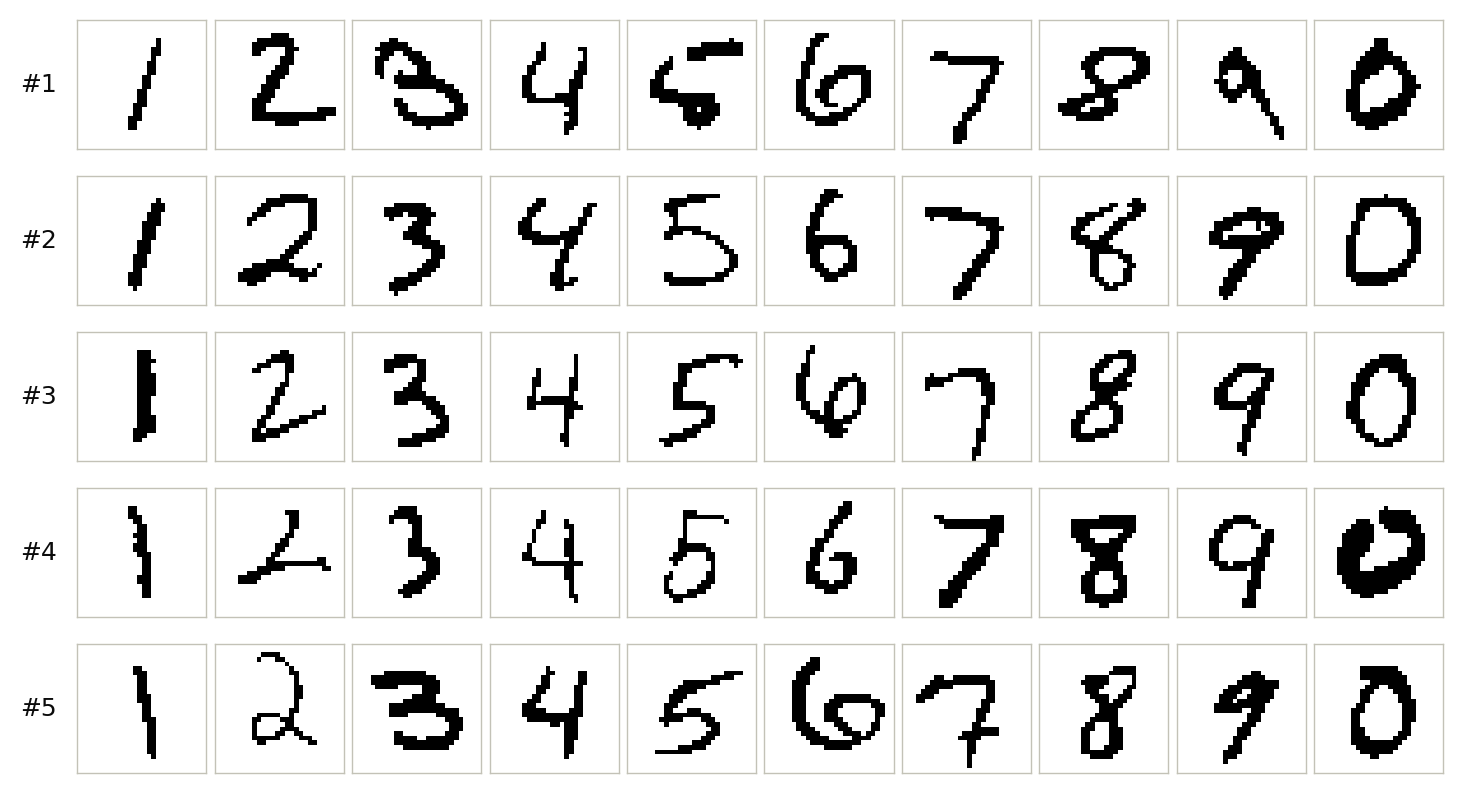

In [9]:
from IPython.display import Image, display
display(Image("figuras/fig_base_dados.png", width=650))

### 7.2 Curvas de treinamento

Épocas: 26 (melhor época na validação: 23), tempo: 34.9 s
E/P: 0.3041 -> 0.0500
Sem momento: E/P após 30 épocas = 0.0694


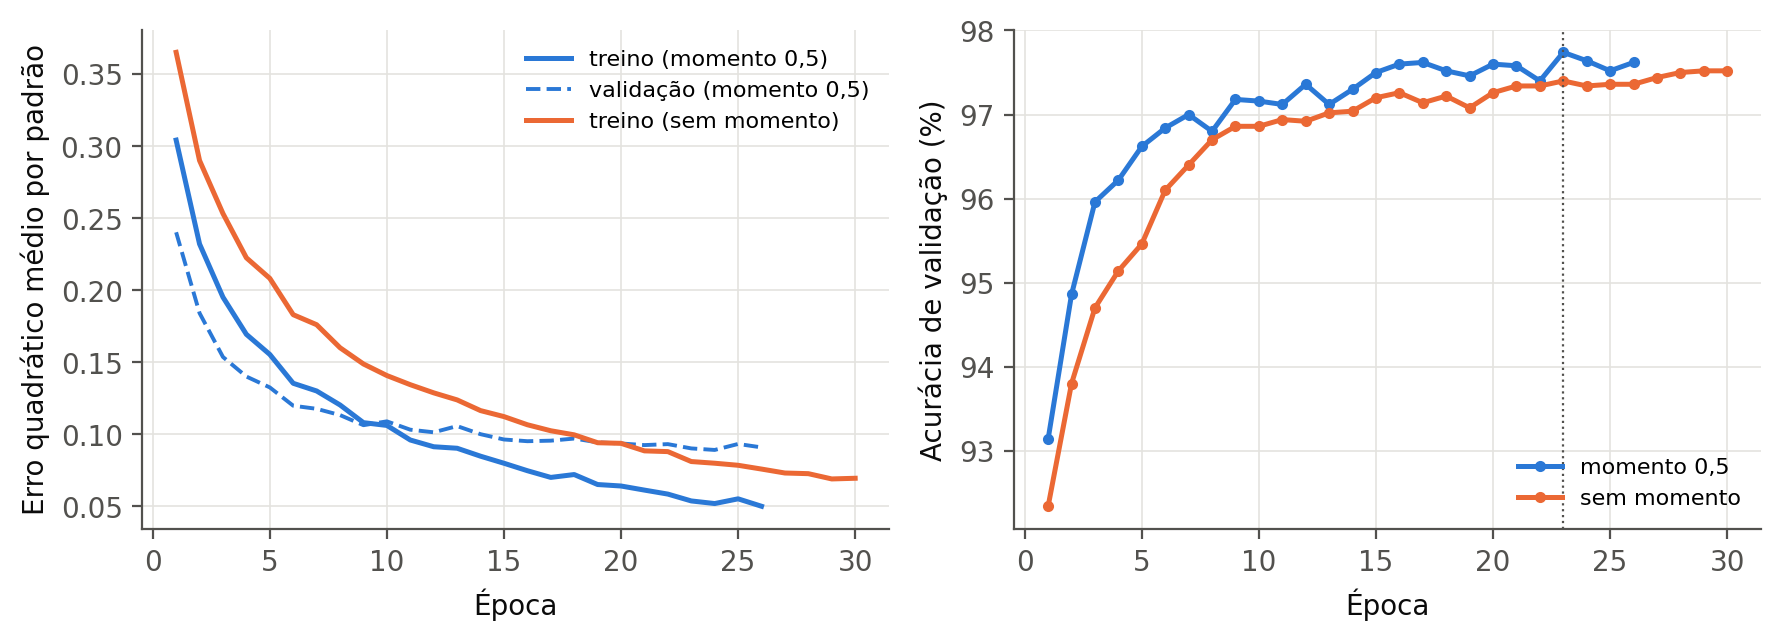

In [10]:
t, sm = resultados["treino"], resultados["sem_momento"]
print(f"Épocas: {t['epocas']} (melhor época na validação: {t['melhor_epoca']}), tempo: {t['tempo_s']} s")
print(f"E/P: {t['erro_treino'][0]:.4f} -> {t['erro_treino'][-1]:.4f}")
print(f"Sem momento: E/P após {len(sm['erro_treino'])} épocas = {sm['erro_treino'][-1]:.4f}")
display(Image("figuras/fig_curva_erro.png", width=800))

### 7.3 Teste e matriz de confusão

Acurácia: treino = 98.70%, teste = 96.93% (307 erros em 10.000)
Acurácia por classe: 0: 98.6%, 1: 98.9%, 2: 96.6%, 3: 96.8%, 4: 97.3%, 5: 96.6%, 6: 97.7%, 7: 95.3%, 8: 95.9%, 9: 95.3%
Maiores confusões: 7->1 (14), 7->2 (12), 4->9 (12), 9->4 (11), 3->5 (11)


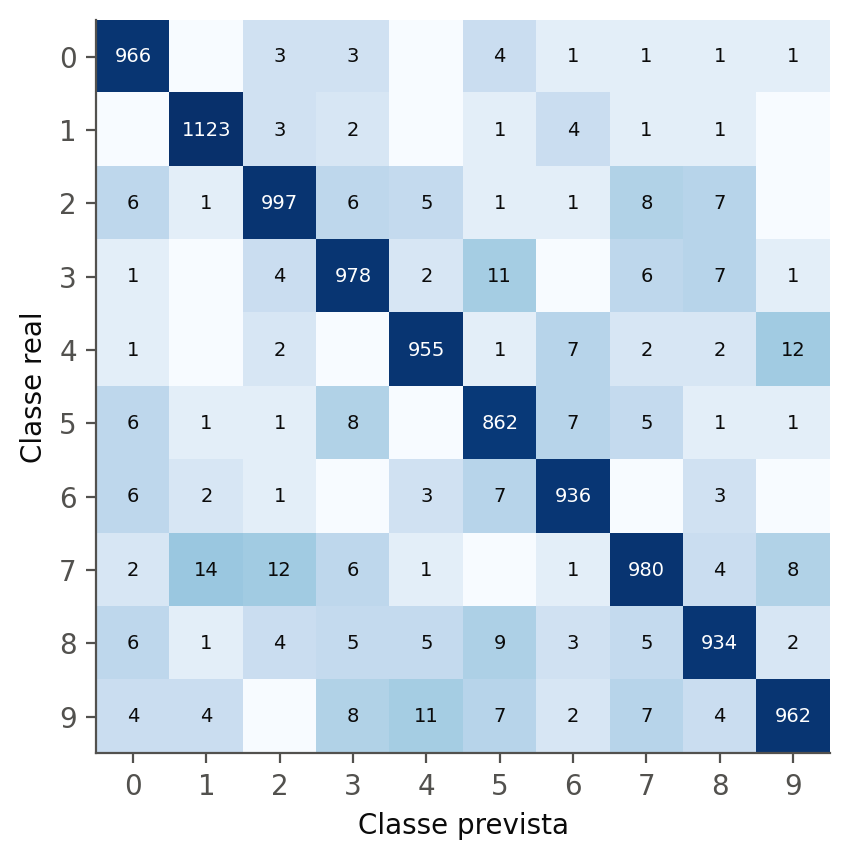

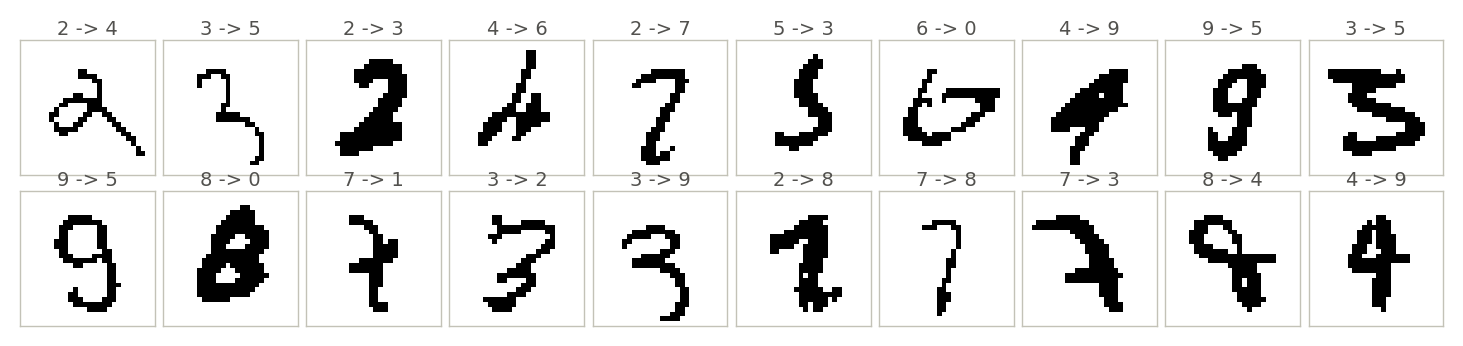

In [11]:
print(f"Acurácia: treino = {100 * t['acuracia_treino']:.2f}%, teste = {100 * t['acuracia_teste']:.2f}% ({t['n_erros_teste']} erros em 10.000)")
print("Acurácia por classe:", ", ".join(f"{k}: {100 * a:.1f}%" for k, a in enumerate(t["acuracia_por_classe"])))
print("Maiores confusões:", ", ".join(f"{c['real']}->{c['previsto']} ({c['casos']})" for c in t["maiores_confusoes"]))
display(Image("figuras/fig_confusao.png", width=480))
display(Image("figuras/fig_erros.png", width=750))

### 7.4 Robustez a ruído

   0% de ruído:  96.93% ± 0.00
   5% de ruído:  95.28% ± 0.15
  10% de ruído:  91.76% ± 0.23
  15% de ruído:  85.56% ± 0.24
  20% de ruído:  76.44% ± 0.37


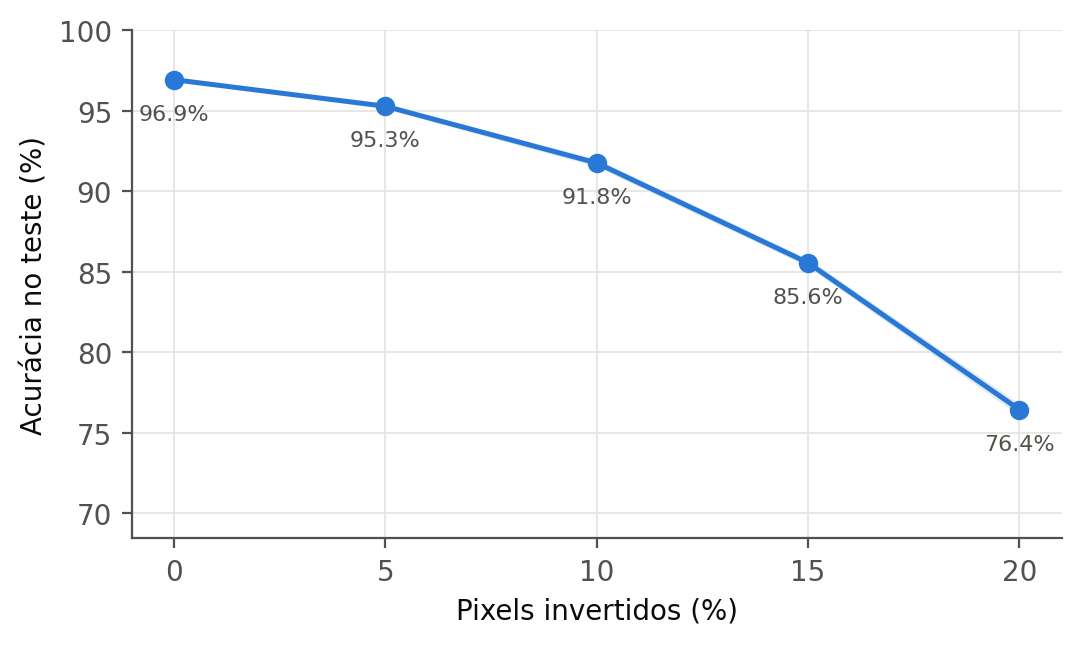

In [12]:
r = resultados["ruido"]
for n, m, d in zip(r["niveis"], r["acuracia_media"], r["acuracia_desvio"]):
    print(f"{100 * n:4.0f}% de ruído: {100 * m:6.2f}% ± {100 * d:.2f}")
display(Image("figuras/fig_ruido.png", width=600))

### 7.5 Dígitos impressos das cinco fontes

Sem serifa negrito (DejaVu Sans Bold)             90%   1->2
Serifada regular (Liberation Serif)               80%   4->5, 8->0
Sem serifa fina (DejaVu Sans ExtraLight)          80%   4->5, 9->8
Manuscrita/cursiva (Kalam)                       100%   -
Serifada condensada (DejaVu Serif Condensed)     100%   -
Geral: 90%


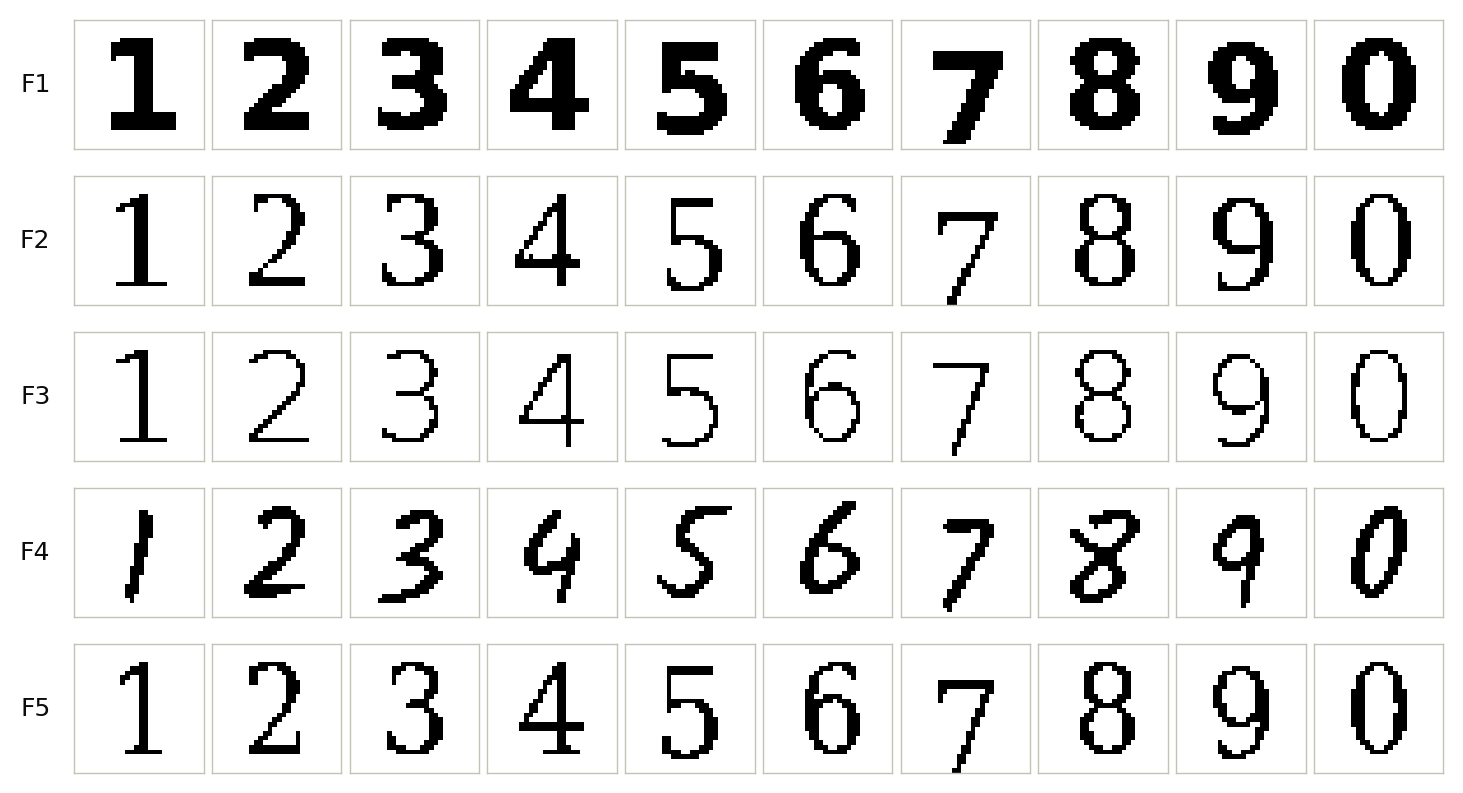

In [13]:
f = resultados["fontes_impressas"]
for rot, a, e in zip(f["rotulos"], f["acuracia_por_fonte"], f["erros_por_fonte"]):
    print(f"{rot:<46s} {100 * a:5.0f}%   {', '.join(e) or '-'}")
print(f"Geral: {100 * f['acuracia_geral']:.0f}%")
display(Image("figuras/fig_fontes_mnist.png", width=650))

### 7.6 Sensibilidade ao número de neurônios ocultos

In [14]:
print(f"{'Ocultos':>8s}{'Pesos':>9s}{'Teste':>9s}{'10% ruído':>11s}{'Tempo (s)':>11s}")
for r in resultados["sensibilidade_ocultos"]:
    print(f"{r['n_ocultos']:>8d}{r['n_pesos']:>9d}{100 * r['acuracia_teste']:>8.2f}%{100 * r['acuracia_teste_ruido10']:>10.2f}%{r['tempo_s']:>11.1f}")

 Ocultos    Pesos    Teste  10% ruído  Tempo (s)
      25    19885   93.43%     85.91%        8.2
      50    39760   95.77%     88.81%       13.7
     100    79510   96.83%     91.92%       26.0
     200   159010   97.21%     92.70%       44.5


## 8. Discussão

- **Desempenho.** Com uma única camada oculta de 100 neurônios e entradas binarizadas, a rede atinge cerca de 97% no teste, o patamar esperado para MLPs simples no MNIST (LeCun et al., 1998). Os erros se concentram em pares de traçado parecido (7/1, 7/2, 4/9, 3/5).
- **Momento.** Com $\mu = 0{,}5$ o erro cai mais rápido e atinge a tolerância antes do limite de épocas. Sem momento, a tolerância não é atingida em 30 épocas, embora a acurácia final seja parecida.
- **Ruído.** A queda é gradual até 10% de pixels invertidos e se acentua a partir de 15%. Com 784 pixels, 20% de inversões já criam muitas manchas de tinta no fundo.
- **Fontes impressas.** A rede nunca viu dígitos impressos e, mesmo assim, reconhece a maioria deles. A fonte manuscrita (Kalam) e a serifada condensada tiveram 100%, o inverso do trabalho com 50 padrões, onde a manuscrita era a mais difícil: aqui é ela que se parece com os dados de treino.
- **Neurônios ocultos.** A acurácia cresce de 25 para 200 neurônios com ganhos decrescentes, enquanto o tempo e o número de pesos crescem linearmente.

Os valores exatos estão em `figuras/resultados.json` e são os mesmos citados no relatório.